In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set a consistent chart style
sns.set_theme(style="whitegrid")

# Set display options

pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",100)

print("Libraries imported sucessfully")

Libraries imported sucessfully


In [4]:
#import file

file_path = Path(r"C:\Users\VISHNU\Downloads\Internship\Dataset\Day2 Netflix Content Type Analysis Dashboard\DATA\Netflix_cleaned.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Dataset shape:",df.shape)

Dataset loaded successfully
Dataset shape: (8790, 10)


In [5]:
#Understand the dataset

# View first five rows
print(df.head())

# Check the number of rows and columns
print("Rows:",df.shape[0])
print("Columns",df.shape[1])

# Check column names
print("\nColumns names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Generate summary statistics
print("\nSummary statistics")
print(df.describe(include="all").T)

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  Tv Show                         Ganglands  Julien Leclercq   
2      s6  Tv Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

                                             country date_added  release_year  \
0  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/25/2021          2020   
1                        ,,,F,,,r,,,a,,,n,,,c,,,e,,,  9/24/2021          2021   
2  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/24/2021          2021   
3                        ,,,B,,,r,,,a,,,z,,,i,,,l,,,  9/22/2021          2021   
4  ,,,U,,,n,,,i,,,t,,,e,,,d,,,S,,,t,,,a,,,t,,,e,,...  9/24/2021          1993   

  rating  duration                                          listed_in  
0 

In [6]:
#Check missing values and duplicates

# Missing values by column

missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

# Duplicate rows
print("\nDuplicate rows:",df.duplicated().sum())

# Missing content type
print("Missing type values:",df["type"].isnull().sum())

# Existing content types
print("\nContent type values:")
print(df["type"].value_counts(dropna=False))

Missing values:
Series([], dtype: int64)

Duplicate rows: 0
Missing type values: 0

Content type values:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


In [8]:
#Step 5 — Prepare the content-type data

# Create a working copy
df_analysis = df.copy()

# Standardize content type
df_analysis["type"] = (
    df_analysis["type"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({"Tv Show": "TV Show"})
)

# Identify valid content types
valid_types = ["Movie","TV Show"]

# Display unexpected or missing values before filtering
invalid_types = df_analysis.loc[
    ~df_analysis["type"].isin(valid_types),
    "type"
].value_counts(dropna=False)

print("Unexpected or missing content types:")
print(invalid_types)

# Keep records with valid content types
df_analysis = df_analysis[
    df_analysis["type"].isin(valid_types)
].copy()

print("\nRows before filtering:", len(df))
print("Rows after filtering:", len(df_analysis))

Unexpected or missing content types:
Series([], Name: count, dtype: int64[pyarrow])

Rows before filtering: 8790
Rows after filtering: 8790


In [9]:
#Step 6 — Calculate the total number of titles
total_titles = len(df_analysis)

if "show_id" in df_analysis.columns:
    unique_titles = df_analysis["show_id"].nunique()
else:
    unique_titles = total_titles


print("Total valid recordes:", total_titles)
print("Unique title IDs:", unique_titles)        

Total valid recordes: 8790
Unique title IDs: 8790


In [11]:
#Step 7 — Calculate Movies and TV Shows
content_counts = (
    df_analysis["type"]
    .value_counts()
    .reindex(["Movie", "TV Show"], fill_value=0)
)

movie_count = int(content_counts["Movie"])
tv_show_count = int(content_counts["TV Show"])
total_content = int(content_counts.sum())

print("Total content records:", total_content)
print("Total Movies:", movie_count)
print("Total TV Shows:", tv_show_count)

Total content records: 8790
Total Movies: 6126
Total TV Shows: 2664


In [12]:
#Step 8 — Calculate content percentages and ratios
if total_content > 0:
    content_percentages = (content_counts / total_content) * 100
else:
    content_percentages = content_counts.astype(float)

movie_percentage = float(content_percentages["Movie"])
tv_show_percentage = float(content_percentages["TV Show"])

if tv_show_count > 0:
    movie_to_tv_ratio = movie_count / tv_show_count
else:
    movie_to_tv_ratio = None

summary = pd.DataFrame({
    "Content Type": ["Movie", "TV Show"],
    "Count": [movie_count, tv_show_count],
    "Percentage": [movie_percentage, tv_show_percentage]
})

print(summary.round(2))

print(f"\nMovie percentage: {movie_percentage:.2f}%")
print(f"TV Show percentage: {tv_show_percentage:.2f}%")

if movie_to_tv_ratio is not None:
    print(f"Movie-to-TV-Show ratio: {movie_to_tv_ratio:.2f}:1")
else:
    print("Movie-to-TV-Show ratio: undefined (no TV Show records)")

  Content Type  Count  Percentage
0        Movie   6126       69.69
1      TV Show   2664       30.31

Movie percentage: 69.69%
TV Show percentage: 30.31%
Movie-to-TV-Show ratio: 2.30:1


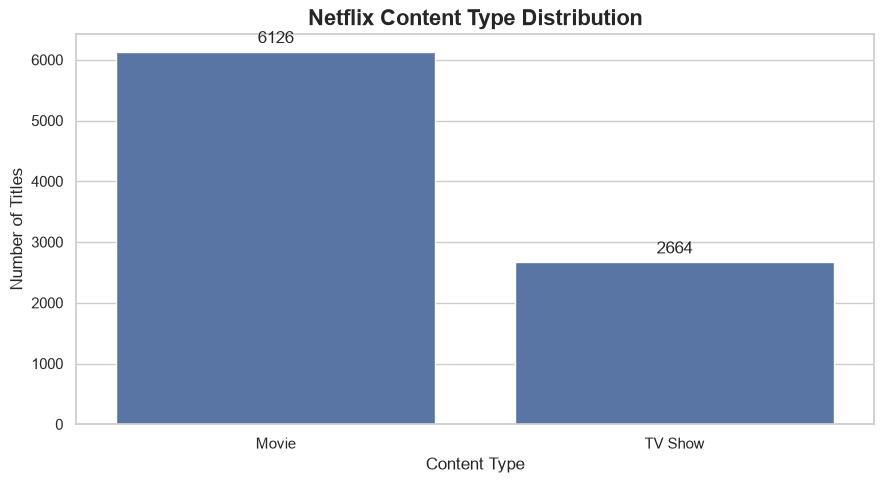

In [13]:
#Visualization 1 — Bar chart: Movies vs. TV Shows
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

ax.set_title("Netflix Content Type Distribution", fontsize=16, weight="bold")
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.savefig(
    "content_type_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

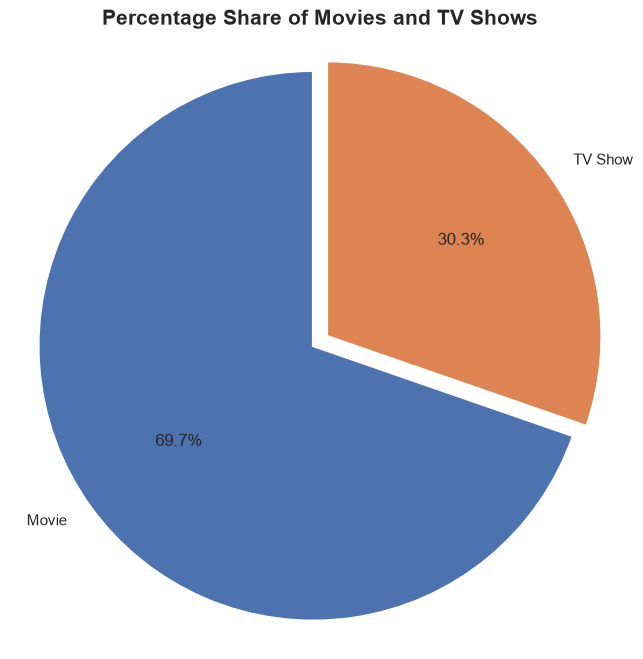

In [14]:
#Visualization 2 — Pie chart: Content type percentages
plt.figure(figsize=(8, 8))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.03, 0.03),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title("Percentage Share of Movies and TV Shows", fontsize=15, weight="bold")
plt.axis("equal")

plt.savefig(
    "content_type_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

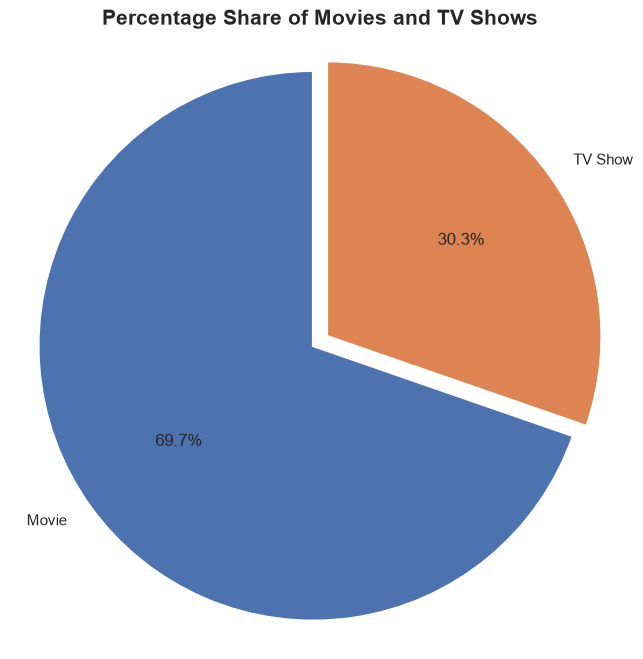

In [15]:
plt.figure(figsize=(8, 8))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.03, 0.03),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title("Percentage Share of Movies and TV Shows", fontsize=15, weight="bold")
plt.axis("equal")

plt.savefig(
    "content_type_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

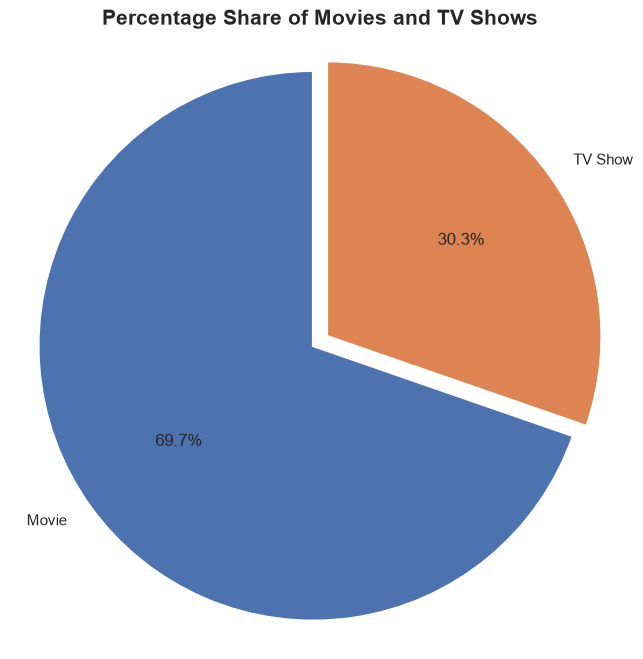

In [16]:
plt.figure(figsize=(8, 8))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.03, 0.03),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title("Percentage Share of Movies and TV Shows", fontsize=15, weight="bold")
plt.axis("equal")

plt.savefig(
    "content_type_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

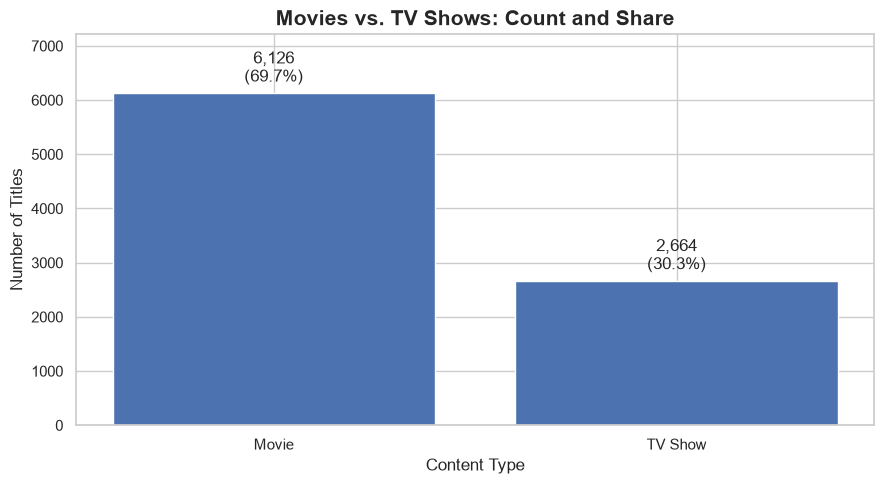

In [17]:
#Visualization 3 — Count and percentage comparison
fig, ax1 = plt.subplots(figsize=(9, 5))

bars = ax1.bar(
    content_counts.index,
    content_counts.values
)

ax1.set_title("Movies vs. TV Shows: Count and Share", fontsize=15, weight="bold")
ax1.set_xlabel("Content Type")
ax1.set_ylabel("Number of Titles")

for bar, percentage in zip(bars, content_percentages.values):
    height = bar.get_height()
    ax1.annotate(
        f"{int(height):,}\n({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax1.set_ylim(0, max(content_counts.max() * 1.18, 1))

plt.tight_layout()
plt.savefig(
    "content_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
#Step 9 — Calculate the difference between Movies and TV Shows
count_difference = abs(movie_count - tv_show_count)

print("Difference between Movies and TV Shows:", count_difference)

if movie_count > tv_show_count:
    print("Movies are more common than TV Shows.")
elif tv_show_count > movie_count:
    print("TV Shows are more common than Movies.")
else:
    print("Movies and TV Shows have equal counts.")

Difference between Movies and TV Shows: 3462
Movies are more common than TV Shows.


In [19]:
#Step 10 — Identify the dominant content type
dominant_type = content_counts.idxmax()
dominant_count = int(content_counts.max())
dominant_percentage = float(content_percentages[dominant_type])

print("Dominant content type:", dominant_type)
print("Number of titles:", dominant_count)
print(f"Share of total content: {dominant_percentage:.2f}%")

Dominant content type: Movie
Number of titles: 6126
Share of total content: 69.69%


In [20]:
#Step 11 — Create a summary table for your report
summary_report = pd.DataFrame({
    "Metric": [
        "Total Content Records",
        "Movie Count",
        "TV Show Count",
        "Movie Percentage",
        "TV Show Percentage",
        "Count Difference",
        "Dominant Content Type"
    ],
    "Value": [
        total_content,
        movie_count,
        tv_show_count,
        round(movie_percentage, 2),
        round(tv_show_percentage, 2),
        count_difference,
        dominant_type
    ]
})

print(summary_report.to_string(index=False))

               Metric  Value
Total Content Records   8790
          Movie Count   6126
        TV Show Count   2664
     Movie Percentage  69.69
   TV Show Percentage  30.31
     Count Difference   3462
Dominant Content Type  Movie


In [21]:
#Step 12 — Export the results
output_folder = Path("reports")
output_folder.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    output_folder / "content_type_summary.csv",
    index=False
)

summary_report.to_csv(
    output_folder / "content_type_analysis_report.csv",
    index=False
)

print("Summary files saved successfully!")

Summary files saved successfully!


In [22]:
#How to calculate the percentage-point difference
percentage_point_difference = abs(
    movie_percentage - tv_show_percentage
)

print(
    f"Percentage-point difference: "
    f"{percentage_point_difference:.2f}"
)

Percentage-point difference: 39.39
